# LDP + SA — distilação federada e avaliação final

## Configuração selecionada e justificação para wearables

**Escolha: LDP P2 (margem binária, C=0,5, Gaussiano, ε total=4 e δ total=10⁻⁵ por cliente/ciclo) + Secure Aggregation de soma única, 24 bits e limiar t=12 em 22 clientes.**

Na deteção de arritmias em wearables, os ECG e as contribuições dos utilizadores são sensíveis. Pretende-se preservar a qualidade da deteção local, limitar a exposição das mensagens e manter um custo de comunicação compatível com dispositivos limitados. A experiência anterior encontrou o maior PR-AUC local médio privado em P2: **0,7982**, face a 0,8018 sem LDP e 0,7964 em P1; P3 obteve 0,7895. Esta é uma seleção exploratória, anterior à abertura do test, não prova estatística de superioridade. Se δ=0 fosse obrigatório, P3 seria a opção compatível entre as testadas; se falsos alarmes fossem o objetivo principal, P1 também mereceria avaliação.

A margem preserva as probabilidades binárias antes da perturbação e utiliza 32 coordenadas no mecanismo local. Após LDP, convertem-se as margens em duas probabilidades por âncora e são estas **64 probabilidades** que entram em SA: não se assume aqui redução de comunicação para 32 valores. Os sinais ECG não são enviados. A CNN1D global completa é redistribuída; o custo do download e o consumo energético no wearable não desaparecem.

SA com soma única revela menos detalhe por origem do que somas separadas. A precisão de 24 bits segue o estudo anterior de quantização; t=12 exige pelo menos 12 respostas e permite até dez desistências, nas condições do protocolo. Isto é um compromisso operacional, não uma configuração universalmente ótima. Neste treino, os 22 clientes participam nas três rondas, sem desistências simuladas.

## Privacidade e atacantes maliciosos: âmbito real

LDP perturba localmente a mensagem antes da agregação, e SA oculta as contribuições individuais no protocolo. **Mantém-se todo o ruído LDP: não se reduz ε/ruído por adicionar SA.** Esta experiência não implementa uma nova prova de privacidade diferencial distribuída.

A implementação SA é uma simulação de investigação que assume **servidor semi-honesto**, sem isolamento de processos, autenticação de produção ou prova de resistência a servidor ativamente malicioso. Usa máscaras, X25519 e partilhas Shamir; não inclui todas as verificações necessárias para segurança maliciosa do protocolo completo. Os testes de rejeição de mensagens inválidas e adulteração de partilhas são verificações funcionais, não uma auditoria criptográfica.

**LDP + SA não impede envenenamento/backdoors:** um cliente malicioso pode enviar uma contribuição válida mas nociva ou recusar colaborar. O clipping é aplicado no código dos clientes honestos; não há prova criptográfica de que um cliente arbitrário o cumpriu. O servidor também não pode garantir a integridade do modelo distribuído contra si próprio. Para afirmar resistência a estes ataques seriam necessárias defesas e avaliação adversarial adicionais. A garantia LDP refere-se ao canal da mensagem preparada com transformações fixas; o pré-processamento histórico usa estatísticas agregadas do fit, pelo que não se demonstra privacidade de ponta a ponta do ECG bruto. Métricas, checkpoints e resultados de test não são divulgações DP.

Referências: [Bonawitz et al., Secure Aggregation](https://eprint.iacr.org/2017/281.pdf); [Bagdasaryan et al., limites perante envenenamento](https://proceedings.mlr.press/v108/bagdasaryan20a.html).

## Protocolo congelado antes do test

- Candidata A: AE+CNN no Icentia; MobileNetV2 no PhysioNet; CNN1D global com adaptadores por origem.
- Cinco seeds (2031–2035), três rondas, dez épocas locais por ronda, três passos do modelo global por ronda; 32 âncoras sintéticas sem rótulos clínicos.
- Os mesmos 22 clientes de treino: 128 exemplos de fit e 32 de holdout por cliente; pesos Icentia 72,73% e PhysioNet 27,27%.
- O objetivo principal durante o treino continua a ser PR-AUC local no holdout do próprio cliente. Sem escolher seed ou ronda por resultados de test.
- **Test final:** todos os exemplos elegíveis dos clientes reservados, sem reequilíbrio artificial: dois clientes Icentia e um PhysioNet, distintos de train/dev. Classe original 3 (ruído) excluída; 0 é normal e 1/2 são anomalia.
- O modelo global de cada seed é avaliado em test após concluir e validar os cinco treinos. Não se treinam modelos nos clientes de test e não se avaliam modelos locais de outros clientes como se fossem avaliação local. Holdout local e test global medem contextos diferentes.
- Normalização ajustada apenas ao fit de treino, ronda final fixa e decisão argmax/0,5. Sem ajuste de limiar nem seleção com test.
- Métricas de test por cliente e origem, e combinadas; pooled AP é distinguida da média de AP por cliente. O conjunto combinado é dominado pela quantidade de Icentia: consultar também cada origem.

O orçamento de cada mensagem é ε=4/3 e δ=10⁻⁵/3. As cinco seeds compõem ε=20 e δ=5×10⁻⁵ por cliente se todas as mensagens forem divulgadas, além de execuções anteriores e tentativas registadas. Não se apresenta a grelha inteira como ε=4. As duas fontes de aleatoriedade segura (ruído e chaves SA) são independentes das seeds de treino. As comparações com a LDP anterior não partilham a mesma realização de ruído e não isolam causalmente o efeito da SA.


In [ ]:
from pathlib import Path
import sys
root=Path.cwd().resolve()
while not (root/'requirements.txt').exists() and root!=root.parent:root=root.parent
sys.path.insert(0,str(root))

{'status': 'complete', 'validated_training_runs': 5, 'test_complete': True, 'signature': '1a45eab0e4b31e1482991725a89ef3eb018ca0a64097235b2409572afa116dfe'}

{'status': 'running', 'kind': 'Softlabels', 'condition': 'P2_LDP_SA', 'seed': 2035, 'round': 3, 'signature': '1a45eab0e4b31e1482991725a89ef3eb018ca0a64097235b2409572afa116dfe'}

### Treino: 5/5 seeds completas

seed,role,pr_auc_ap,recall,far,f1,roc_auc
2031,local,0.789818,0.688561,0.147168,0.663661,0.849170
2031,global,0.445201,0.251748,0.221846,0.220536,0.510684
2032,local,0.789989,0.720529,0.152935,0.704393,0.834900
2032,global,0.503612,0.819493,0.797581,0.408116,0.548788
2033,local,0.818607,0.657280,0.112763,0.658377,0.853588
2033,global,0.301834,0.017483,0.070039,0.027273,0.277647
2034,local,0.787856,0.624938,0.156717,0.621426,0.844683
2034,global,0.471244,0.920017,0.939170,0.452846,0.542922
2035,local,0.808049,0.647040,0.093272,0.657726,0.845902
2035,global,0.445431,0.975524,0.902223,0.469287,0.519362


pr_auc_ap              recall  ...       far        f1          
            mean       std      mean  ...       std      mean       std
role                                  ...                              
global  0.433464  0.077388  0.596853  ...  0.408753  0.315612  0.189199
local   0.798864  0.013747  0.667670  ...  0.028051  0.661117  0.029469

[2 rows x 8 columns]

seed,upload_KiB,download_KiB,max_quantization_error,integer_sums_verified
2031,341.859375,7333.90625,0.0,True
2032,341.859375,7333.90625,0.0,True
2033,341.859375,7333.90625,0.0,True
2034,341.859375,7333.90625,0.0,True
2035,341.859375,7333.90625,0.0,True


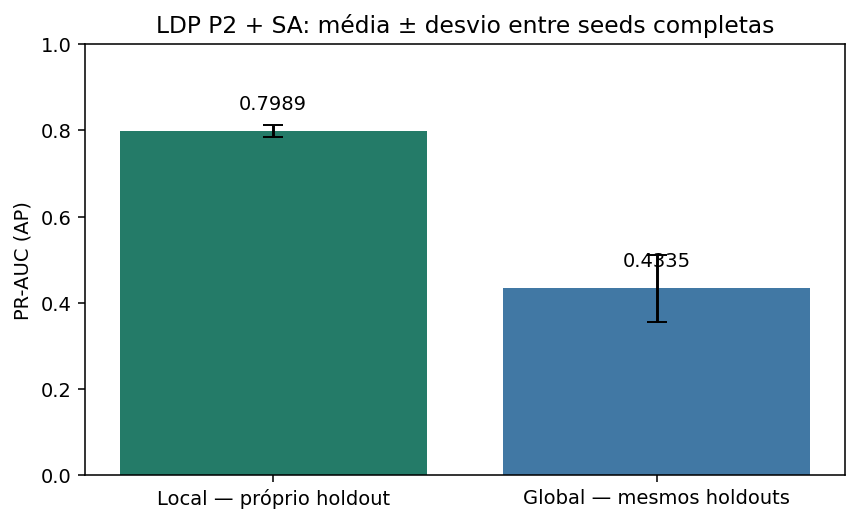

### Avaliação final em test — modelo global

**Avaliação completa e validada.**

seed,dataset,client,scope,n_examples,pr_auc_ap,recall,far,f1
2031,icentia11k,client_18,client,238103,0.030435,0.011993,0.005770,0.019100
2032,icentia11k,client_18,client,238103,0.056846,1.000000,0.999996,0.045180
2033,icentia11k,client_18,client,238103,0.011728,0.022170,0.919256,0.001112
2034,icentia11k,client_18,client,238103,0.590502,1.000000,0.999996,0.045180
2035,icentia11k,client_18,client,238103,0.532478,0.967109,0.549415,0.076786
2031,icentia11k,client_19,client,183619,0.233404,0.045913,0.014219,0.083213
2032,icentia11k,client_19,client,183619,0.132290,0.996231,0.996632,0.330213
2033,icentia11k,client_19,client,183619,0.132722,0.375120,0.728767,0.173364
2034,icentia11k,client_19,client,183619,0.173468,0.999670,0.999314,0.330569
2035,icentia11k,client_19,client,183619,0.291640,0.982559,0.993121,0.327194


pr_auc_ap            ...        f1          
                                  mean       std  ...      mean       std
dataset       scope                               ...                    
combined      all_pooled      0.144914  0.093609  ...  0.149293  0.069472
icentia11k    dataset_pooled  0.144024  0.093395  ...  0.147512  0.070604
physionet2017 dataset_pooled  0.399267  0.027543  ...  0.375474  0.218246

[3 rows x 8 columns]

{'status': 'complete', 'signature': '1a45eab0e4b31e1482991725a89ef3eb018ca0a64097235b2409572afa116dfe', 'seed_count': 5, 'evaluated': 'all prepared test examples except original noise class 3', 'normalization': 'training fit only', 'fixed_round': 3, 'fixed_threshold': 0.5, 'selection_on_test': False, 'local_models_on_unseen_clients': False, 'n_examples_once': 422752, 'test_metrics_recomputed': True}

{'weighted_sa_sum_matches_reference': True, 'sa_quantization_max_error': 2.01822803913565e-07, 'ldp_before_aggregation_and_cycle_budget': True, 'invalid_messages_rejected_in_simulator': True, 'dropout_sum_and_below_threshold_refusal': True, 'tampered_share_ciphertext_rejected': True, 'scope': 'functional checks only, no adversarial training or malicious-security proof'}

**Limite da conclusão:** estas métricas medem utilidade com participação honesta, não resistência a ataques maliciosos. A escolha foi feita em resultados exploratórios anteriores; test é avaliação final deste protocolo, não nova oportunidade de selecionar parâmetros.

In [1]:
from support.ldp_sa.notebook import render_results
render_results()

## Síntese — Soft labels com e sem SA e LDP

Comparação das quatro configurações na **ronda 3**, com as mesmas **cinco seeds (2031–2035)** e os mesmos **22 clientes e holdouts**. Cada métrica é ponderada pelo número de exemplos de fit dos clientes; apresentam-se a média e o desvio padrão amostral entre seeds.

A primeira linha mostra os **modelos locais**; a segunda, o **modelo global** nos mesmos holdouts. Estes resultados **não são do test final** apresentado acima. A PR-AUC é a média ponderada das AP por cliente, não AP de previsões agrupadas.

LDP usa **P2: Gaussiano, margem, C=0,5, ε=4 e δ=10⁻⁵ por cliente/ciclo**. SA usa **24 bits e limiar 12/22**. O ruído LDP é independente nas duas execuções privadas; as diferenças entre Só LDP e SA + LDP não isolam o efeito da SA.


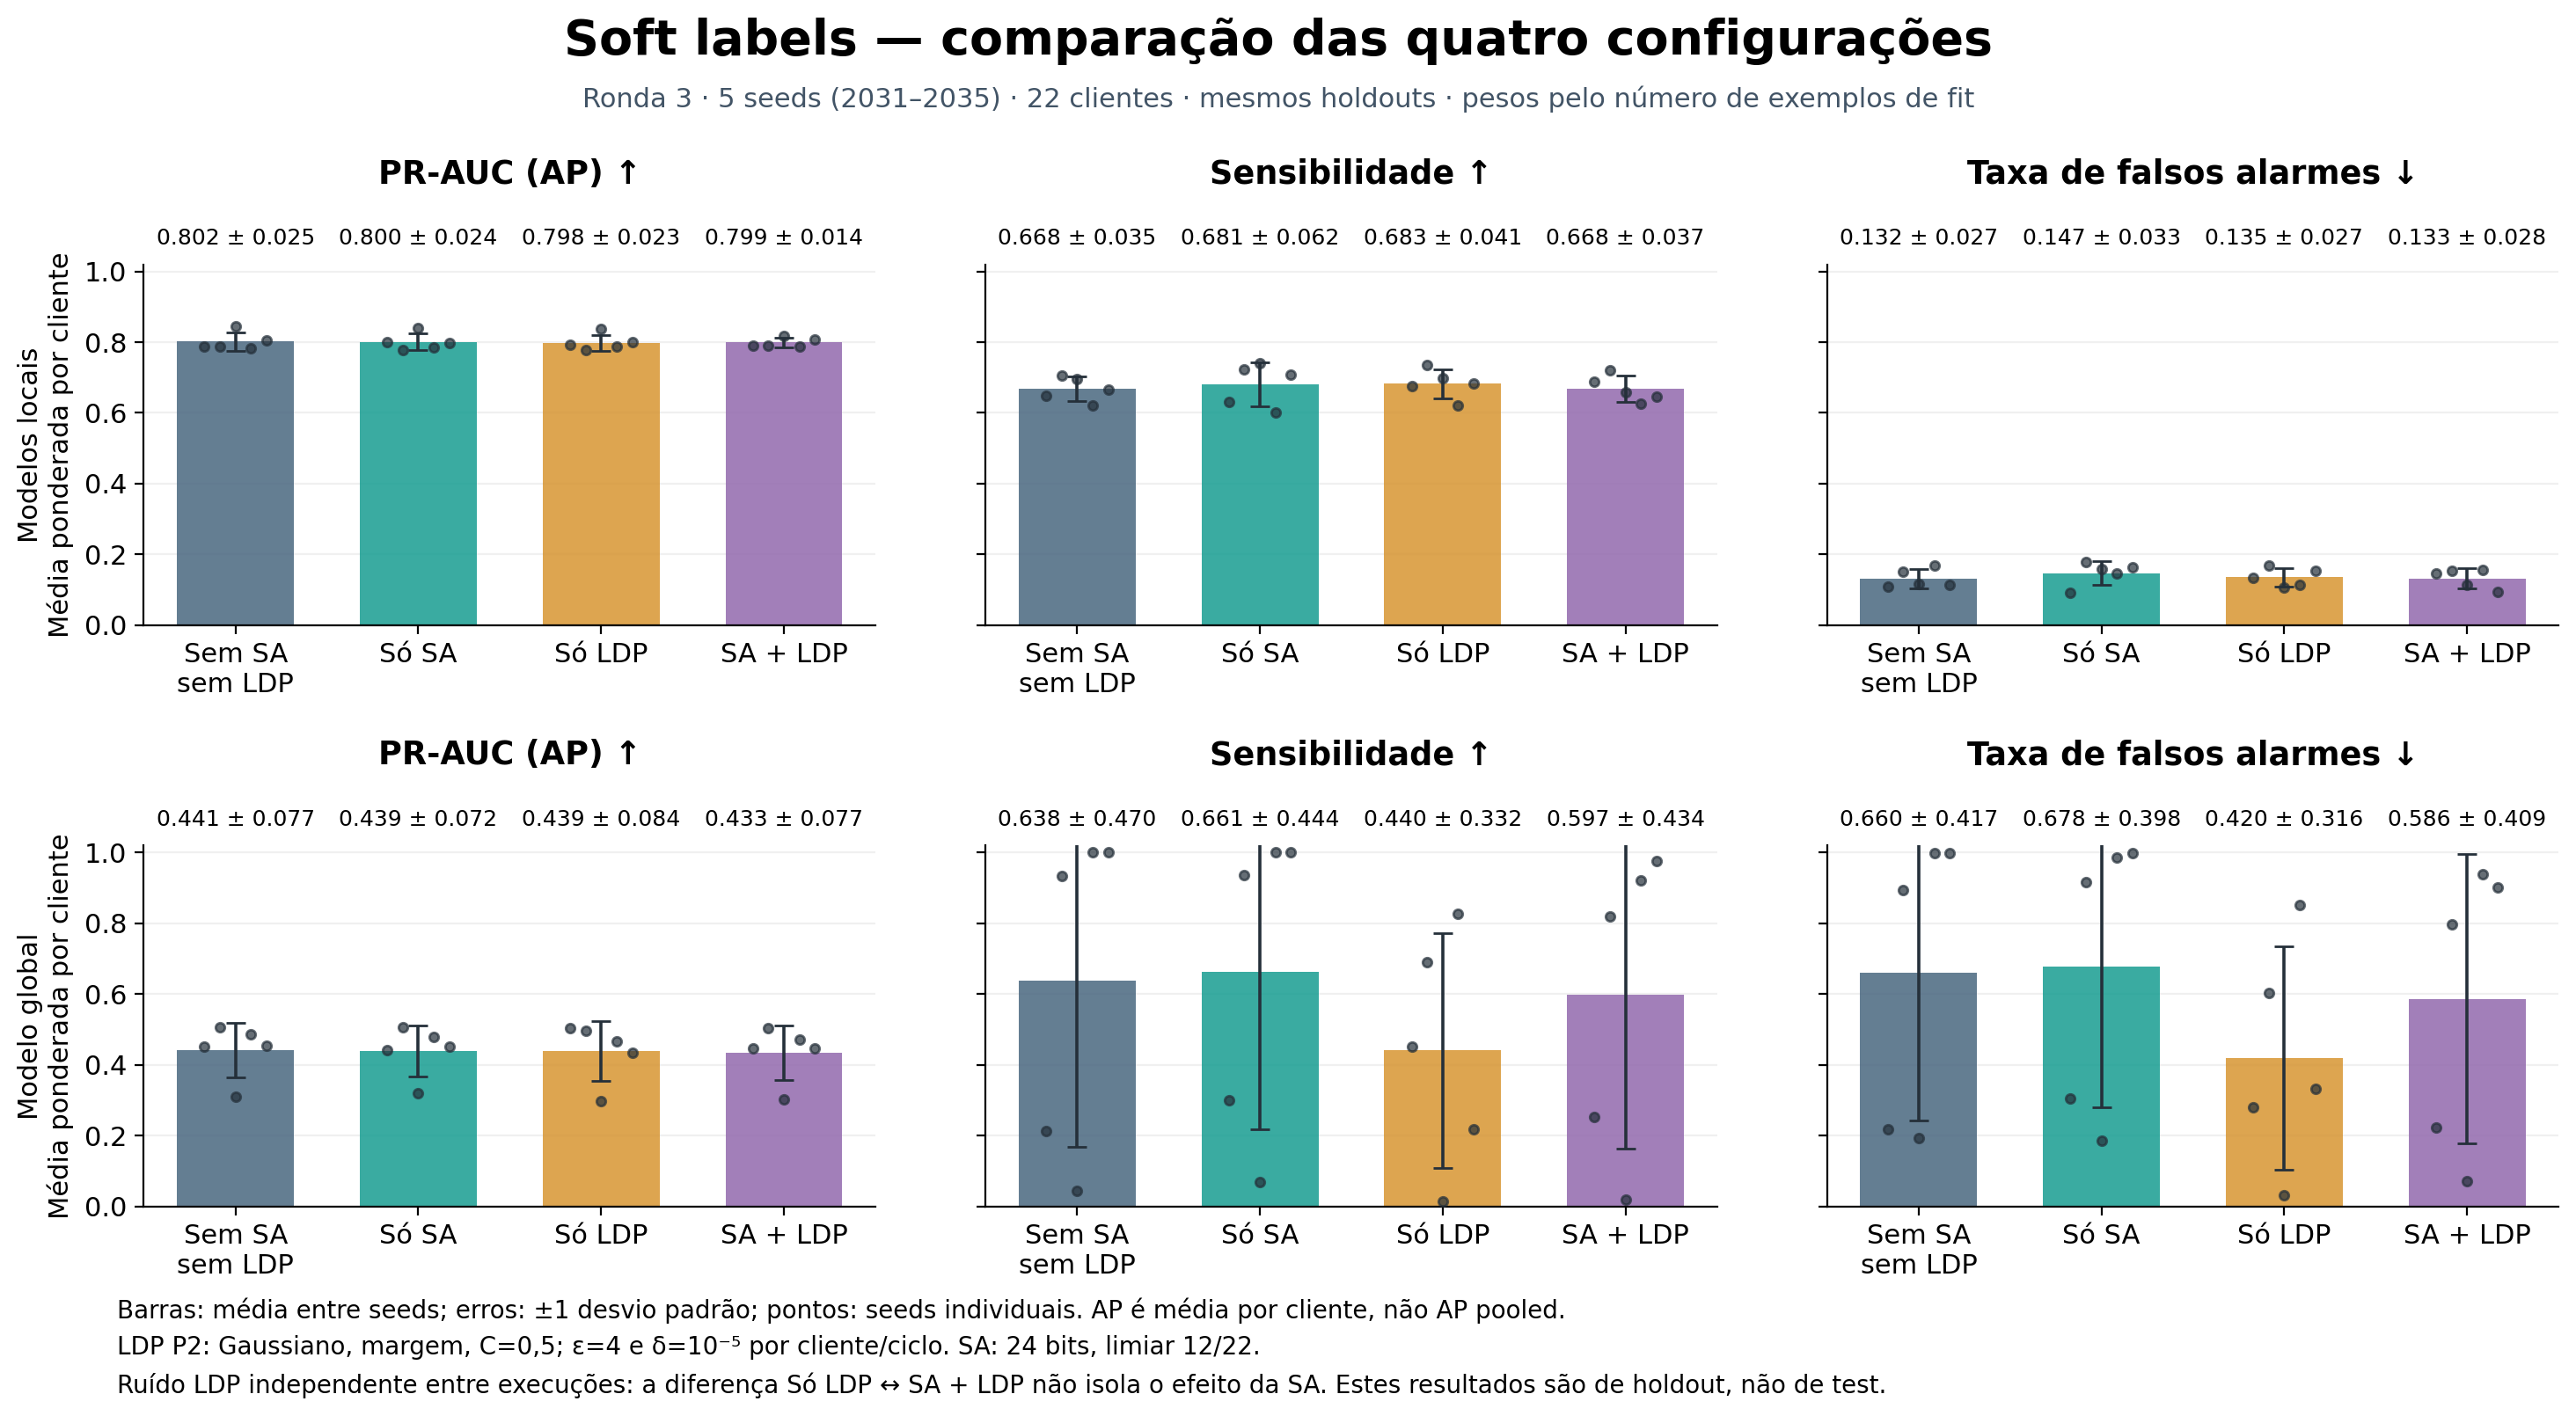

pr_auc_ap          recall             far        
                             mean     std    mean     std    mean     std
condition        role                                                    
Sem SA / sem LDP local     0.8018  0.0255  0.6676  0.0346  0.1316  0.0267
                 global    0.4410  0.0769  0.6381  0.4699  0.6599  0.4174
Só SA            local     0.8004  0.0237  0.6810  0.0618  0.1475  0.0334
                 global    0.4388  0.0717  0.6613  0.4435  0.6779  0.3982
Só LDP (P2)      local     0.7982  0.0227  0.6826  0.0411  0.1352  0.0266
                 global    0.4393  0.0842  0.4401  0.3324  0.4197  0.3160
SA + LDP (P2)    local     0.7989  0.0137  0.6677  0.0374  0.1326  0.0281
                 global    0.4335  0.0774  0.5969  0.4336  0.5862  0.4088

In [ ]:
from support.softlabels_privacy_comparison import main as criar_comparacao, OUT
from IPython.display import display, Image
import pandas as pd

# Apenas lê resultados concluídos e regenera o gráfico; não executa treino.
criar_comparacao()
display(Image(filename=str(OUT / "comparacao_softlabels_privacidade.png")))
resumo = pd.read_csv(OUT / "resumo.csv", header=[0, 1], index_col=[0, 1])
display(resumo.round(4))


**Leitura:** o PR-AUC local é semelhante nas quatro condições (aproximadamente 0,80). O PR-AUC global fica entre 0,434 e 0,441 e a sensibilidade e os falsos alarmes globais variam bastante entre seeds. Estas médias não demonstram equivalência estatística nem superioridade de uma condição.

Os ficheiros PNG, PDF, CSV e as fontes da comparação estão em `artifacts/softlabels_overview/comparacao_privacidade/`, a partir da raiz do projeto. O código que reproduz a figura está em `support/softlabels_privacy_comparison.py`.


## Trade-off entre utilidade e privacidade

O gráfico relaciona a **utilidade medida (PR-AUC)** com os **mecanismos de proteção** de cada configuração. SA e LDP não são níveis de uma mesma escala: SA oculta contribuições durante a agregação, nas hipóteses do protocolo; LDP limita a informação da mensagem preparada através de perturbação local. A combinação mantém o mesmo orçamento LDP e acrescenta SA.

A tabela apresenta a perda de AP face à referência, multiplicada por 100 (valores positivos indicam perda). As barras de erro são desvios padrão entre cinco seeds, não intervalos de confiança. Usam-se os mesmos holdouts da comparação anterior; não se misturam métricas de test.


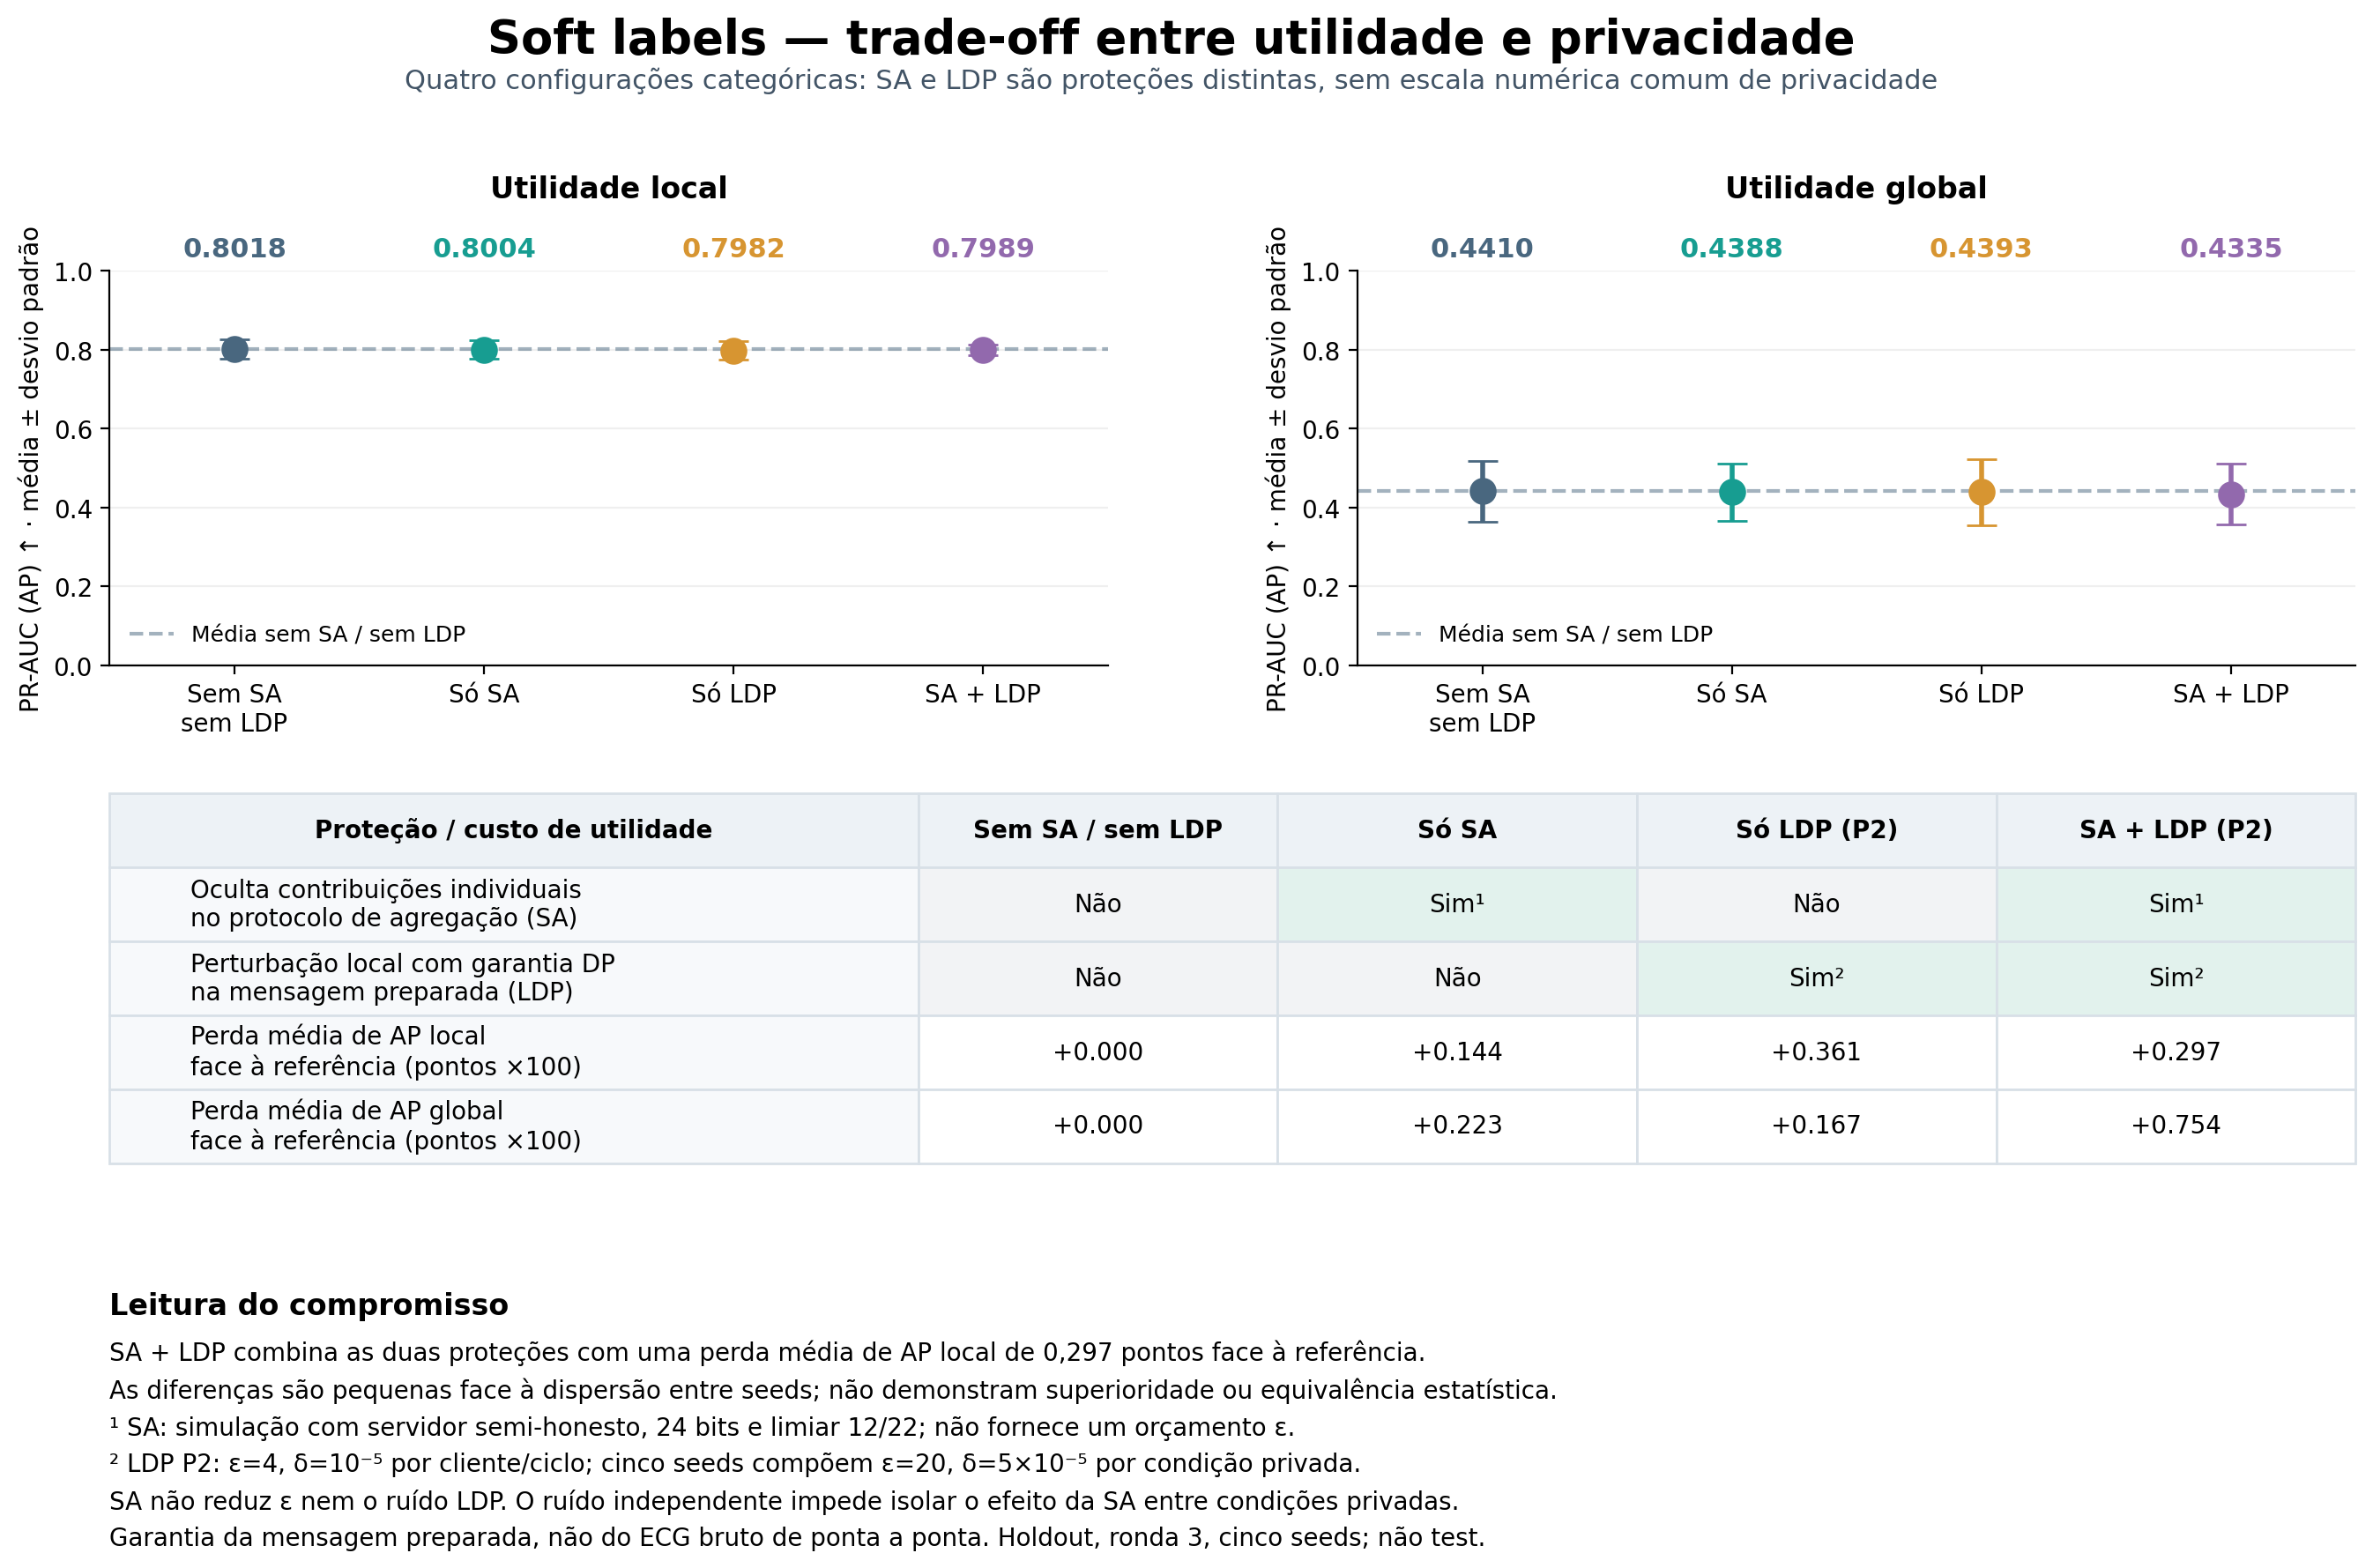

In [ ]:
from support.softlabels_privacy_tradeoff import main as criar_tradeoff
from support.softlabels_privacy_comparison import OUT
from IPython.display import display, Image

# Regenera apenas a figura a partir dos resultados guardados, sem treino.
criar_tradeoff()
display(Image(filename=str(OUT / "tradeoff_utilidade_privacidade.png")))


**Interpretação:** SA + LDP combina as duas proteções com AP local média de **0,7989**, face a **0,8018** sem proteção adicional: perda observada de **0,297 pontos de AP ×100** (cerca de **99,63% da AP de referência**). A AP global passa de **0,4410** para **0,4335**, perda de **0,754 pontos**. A dispersão entre seeds é maior do que estas diferenças; não se conclui equivalência estatística nem que SA melhora a utilidade.

**Âmbito da privacidade:** ε=4 e δ=10⁻⁵ são por cliente/ciclo. As cinco seeds privadas compõem ε=20 e δ=5×10⁻⁵ por condição, além de divulgações e tentativas anteriores. Executar e divulgar ambas as condições privadas exige compor também os respetivos orçamentos. SA não reduz esse orçamento. A garantia LDP é da mensagem preparada, sem demonstração de privacidade de ponta a ponta do ECG bruto. A SA é uma simulação com servidor semi-honesto e não estabelece resistência a servidor ativamente malicioso ou a envenenamento.

Assim, **SA + LDP é um compromisso plausível para combinar as duas proteções preservando a utilidade local observada**, condicionado às hipóteses acima; este estudo não quantifica uma pontuação global de privacidade nem demonstra uma solução ótima.


## Gráficos de privacidade — garantias e exposição

**A:** presença das duas proteções, sem as somar numa pontuação artificial. **B:** acesso do servidor às mensagens individuais ou apenas ao agregado, nas hipóteses de SA; com LDP, as mensagens são previamente perturbadas. **C–D:** composição dos orçamentos ε e δ nas cinco seeds privadas, por cliente e por condição.

Só LDP e SA + LDP têm **as mesmas curvas ε/δ**: SA acrescenta ocultação das contribuições durante a agregação, sem reduzir o orçamento LDP. As configurações sem LDP não entram nestas curvas porque **não têm uma garantia DP estabelecida**; representá-las com ε=0 seria incorreto.

Estes gráficos descrevem as garantias e parâmetros do protocolo. Não foram medidos sucesso de ataques de inferência, reconstrução ou fuga de informação; não se apresentam esses resultados como se tivessem sido avaliados. A composição mostrada exclui execuções históricas e outras divulgações.


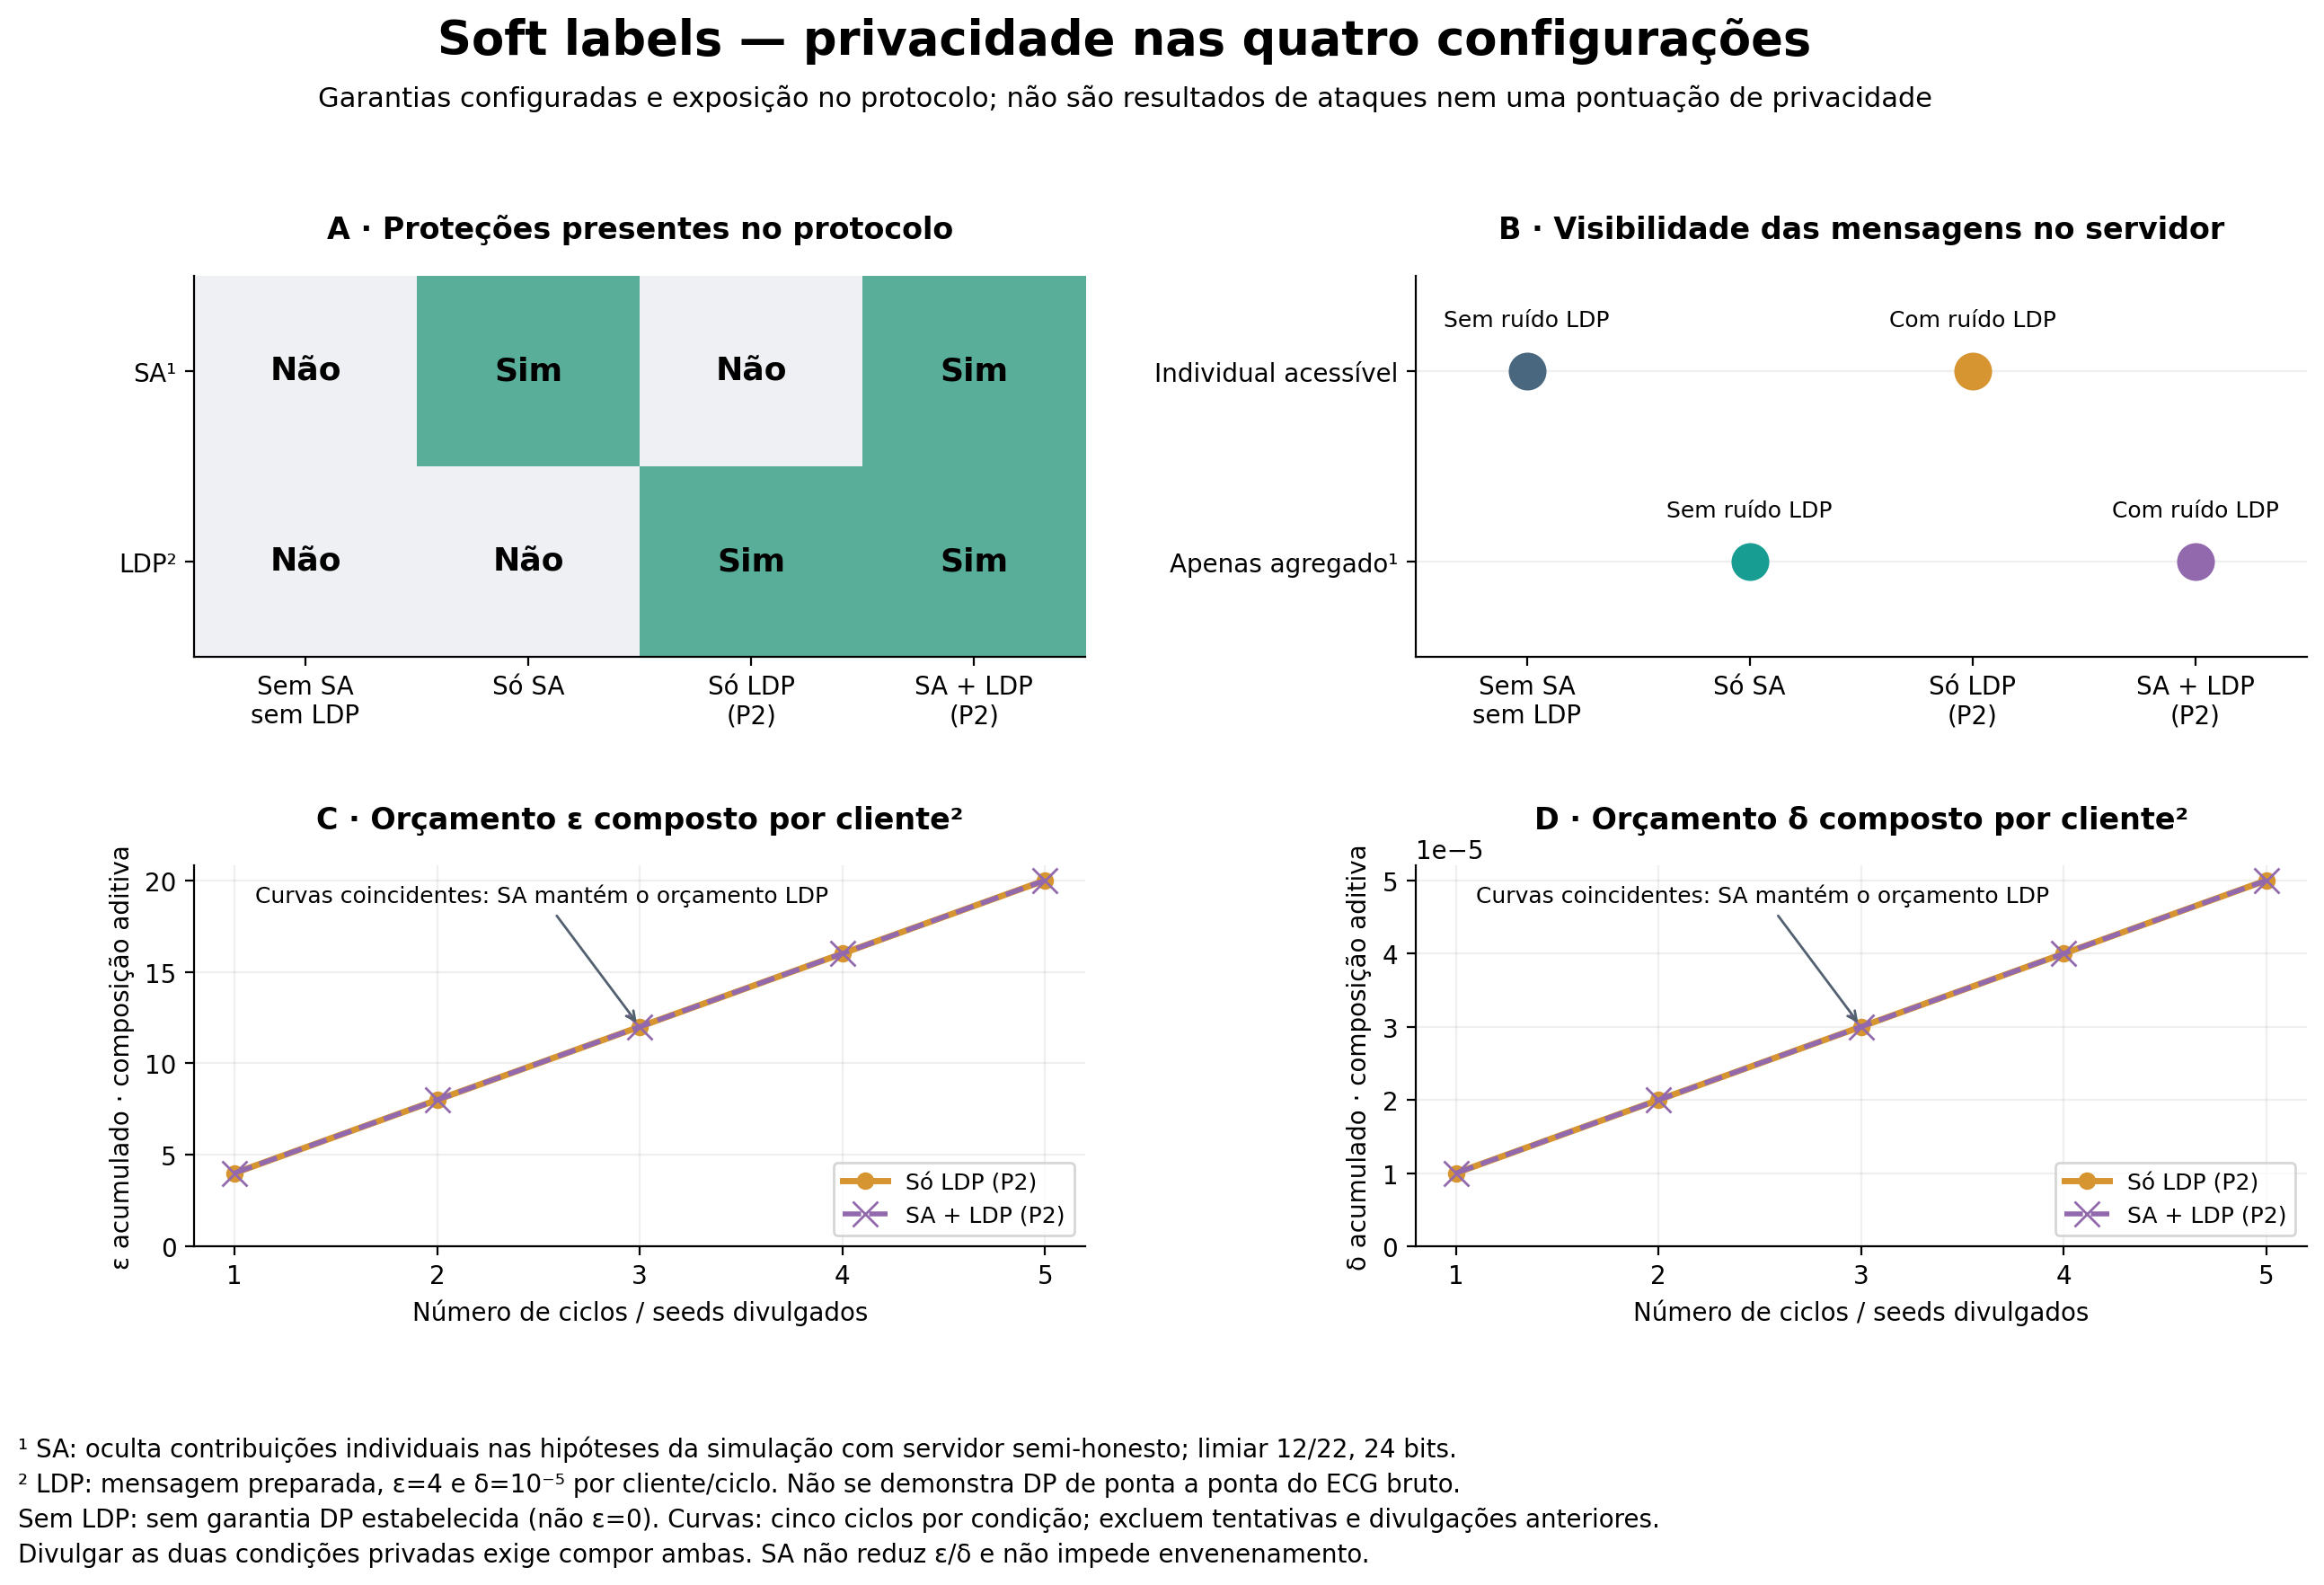

In [ ]:
from support.softlabels_privacy_panels import main as criar_graficos_privacidade
from support.softlabels_privacy_comparison import OUT
from IPython.display import display, Image

criar_graficos_privacidade()
display(Image(filename=str(OUT / "privacidade_quatro_configuracoes.png")))


## Conclusão — configuração mais adequada ao cenário de wearables

Para o cenário estudado — **deteção de arritmias em wearables, com dados de saúde sensíveis e aprendizagem federada** — a configuração **Soft labels com LDP P2 e Secure Aggregation (SA)** constitui o compromisso mais adequado entre as quatro alternativas avaliadas, quando o objetivo é combinar proteção das mensagens individuais com preservação da utilidade dos modelos locais. Esta recomendação resulta das prioridades do cenário e dos resultados observados; não demonstra que esta configuração seja universalmente ótima.

Os sinais ECG e as contribuições derivadas dos utilizadores podem revelar informação sensível sobre o seu estado de saúde. Manter os sinais localmente reduz a necessidade de os centralizar, mas não torna automaticamente privadas as mensagens transmitidas durante o treino. **LDP perturba a mensagem preparada antes da transmissão**, oferecendo a garantia definida pelo mecanismo; **SA oculta as contribuições individuais durante a agregação**, nas hipóteses do protocolo. Assim, as duas técnicas têm funções complementares. Só SA não estabelece uma garantia de privacidade diferencial; só LDP permite ao servidor observar contribuições individuais já perturbadas. A combinação mantém o orçamento LDP e acrescenta a proteção da agregação.

Na comparação na ronda 3, com os mesmos 22 clientes e cinco seeds, a configuração combinada obteve **PR-AUC local média de 0,7989**, face a **0,8018** sem SA nem LDP. A redução observada é de **0,00297 de AP**, equivalente a cerca de **0,37% da referência**: preserva aproximadamente **99,63% da AP local de referência**. A sensibilidade local média foi **0,6677**, praticamente igual à referência (**0,6676**), e a taxa de falsos alarmes foi **0,1326**, face a **0,1316**. Estes resultados sugerem que, neste protocolo, a proteção adicional foi obtida com uma alteração pequena da utilidade local média. As diferenças são pequenas face à dispersão entre seeds; não se demonstra equivalência estatística. Como as execuções privadas usam ruído independente, também não se atribuem diferenças entre Só LDP e SA + LDP exclusivamente à SA.

Esta preservação da utilidade local é relevante para uma arquitetura que pretenda realizar deteção no próprio wearable. Contudo, os resultados apresentados são de **holdout nos clientes de treino**, não uma demonstração de desempenho em dispositivos reais ou de generalização dos modelos locais a novos utilizadores. Uma sensibilidade próxima de 0,668 e uma taxa de falsos alarmes próxima de 0,133 também não bastam para afirmar adequação clínica. Importa avaliar os casos não detetados e a carga de alarmes em condições reais de utilização.

A conclusão é mais limitada para o **modelo global**: a PR-AUC média nos mesmos holdouts passa de **0,4410** para **0,4335** e existe elevada variabilidade entre seeds, sobretudo na sensibilidade e nos falsos alarmes. Por isso, a escolha da combinação não deve ser interpretada como validação do modelo global para deteção autónoma de arritmias. A avaliação final de test de LDP + SA, apresentada neste notebook, complementa a análise, mas não constitui uma comparação de test das quatro configurações.

Em termos operacionais, a distilação por soft labels transmite contribuições sobre âncoras sintéticas, sem enviar os ECG brutos. Ainda assim, **não foram medidos consumo energético, autonomia, latência ou custo computacional num wearable real**. SA acrescenta comunicação e operações criptográficas; a distribuição da CNN1D global também tem custo. A configuração usada — **24 bits, limiar de 12 em 22 clientes**, sem desistências no treino — deve ser validada com conectividade intermitente e recursos limitados antes de se afirmar viabilidade no dispositivo.

A recomendação adota **LDP P2: mecanismo Gaussiano, representação por margem, C=0,5, ε=4 e δ=10⁻⁵ por cliente/ciclo**. Estes valores não são um selo de segurança clínica nem um orçamento vitalício: divulgar as cinco seeds privadas compõe **ε=20 e δ=5×10⁻⁵ por condição**, além das restantes execuções e divulgações. SA não reduz esse orçamento. A garantia refere-se à mensagem preparada, sem demonstração de privacidade de ponta a ponta do ECG bruto. A implementação de SA é uma simulação com servidor semi-honesto; não estabelece proteção contra servidor ativamente malicioso, envenenamento ou backdoors.

**Recomendação final:** usar **Soft labels + LDP P2 + SA como configuração de referência para continuar o desenvolvimento experimental**, por combinar as duas proteções e preservar a utilidade local observada. Para passar a uma solução de saúde em wearables, continuam necessárias validação em novos utilizadores e dispositivos, avaliação clínica da sensibilidade e dos falsos alarmes, medição do custo energético e de comunicação, gestão do orçamento de privacidade ao longo do tempo e reforço da segurança do protocolo. A escolha é um compromisso fundamentado para este estudo, não uma configuração já validada para utilização clínica.


## Figura de síntese para o relatório

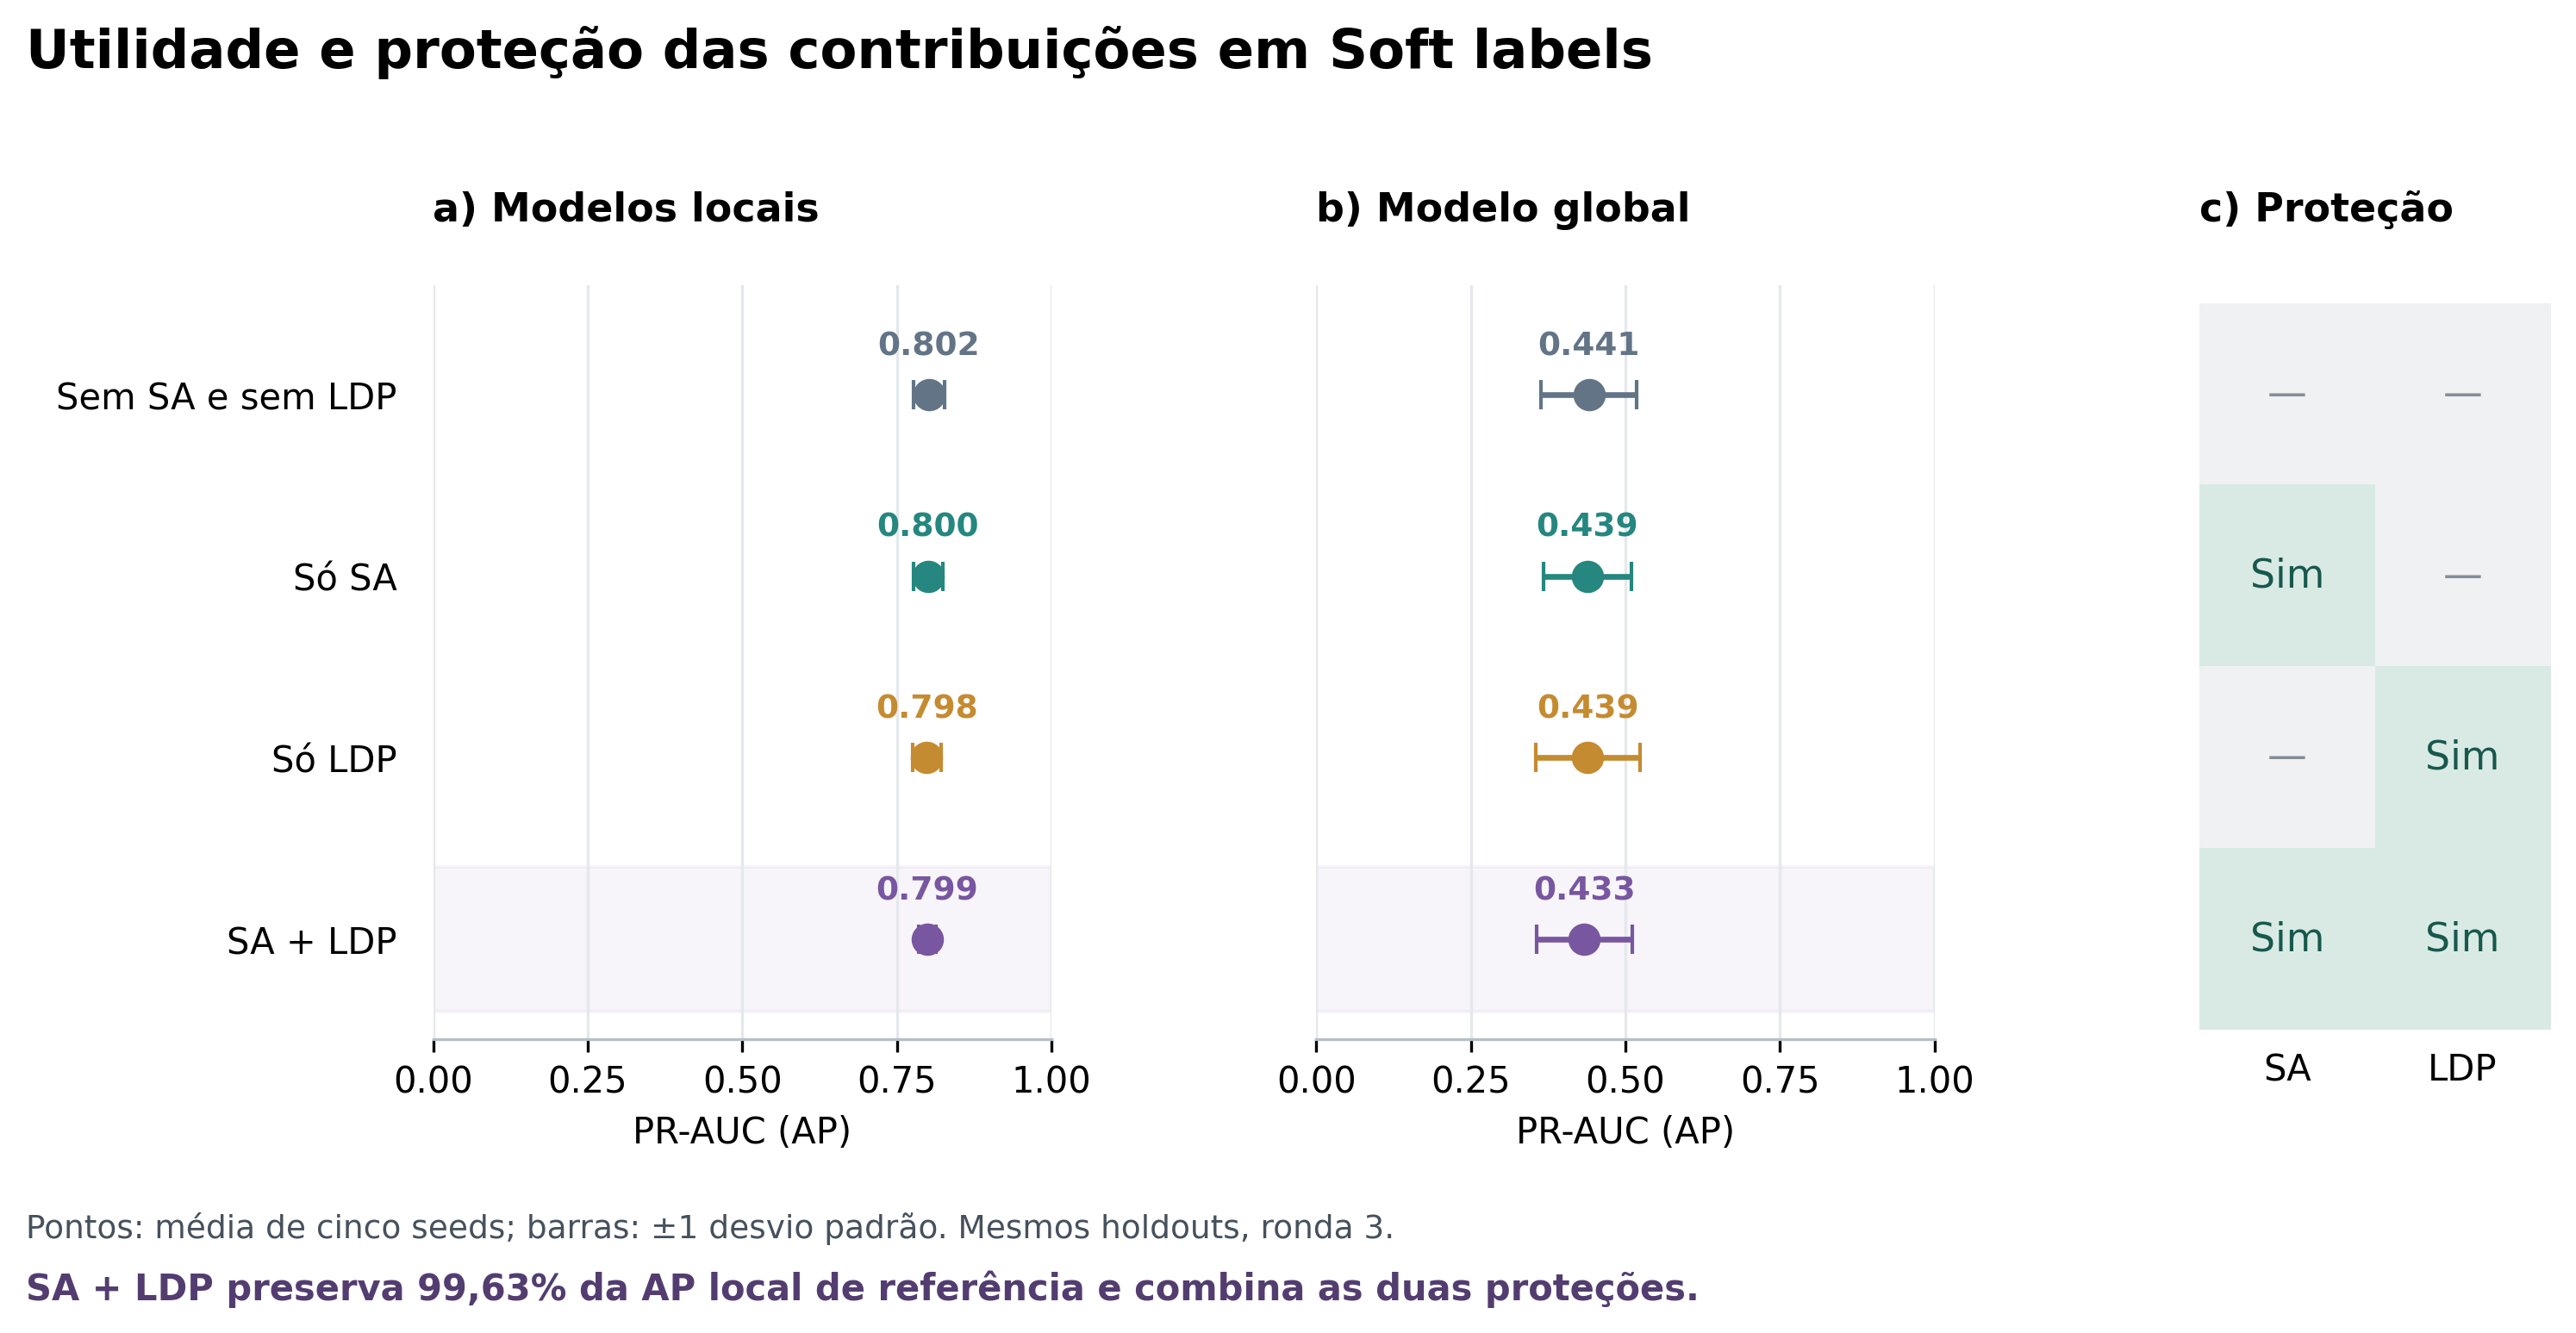

In [ ]:
from IPython.display import display, Image
from support.softlabels_privacy_comparison import OUT
display(Image(filename=str(OUT / "resumo_relatorio.png")))

**Figura — Utilidade e proteção das contribuições nas quatro configurações de Soft labels.** (a–b) PR-AUC (AP) local e global na ronda 3, nos mesmos holdouts dos 22 clientes de treino. Cada ponto representa a média de cinco seeds (2031–2035); as barras representam ±1 desvio padrão amostral entre seeds. Em cada seed, calcula-se a média das métricas por cliente ponderada pelo número de exemplos de fit; não se trata de AP pooled nem de resultados de test. (c) Presença dos mecanismos de proteção: SA oculta contribuições individuais durante a agregação nas hipóteses da simulação com servidor semi-honesto; LDP perturba a mensagem preparada. “Sim” indica a presença do mecanismo, não uma medição de eficácia contra ataques. LDP P2 usa mecanismo Gaussiano, margem, C=0,5, ε=4 e δ=10⁻⁵ por cliente/ciclo; SA usa 24 bits e limiar 12/22. As condições com LDP têm o mesmo orçamento: SA não reduz ε/δ. A composição de cinco seeds por condição privada corresponde a ε=20 e δ=5×10⁻⁵, além de outras divulgações. O ruído independente entre condições privadas impede isolar o efeito da SA; as diferenças observadas não demonstram equivalência estatística. A garantia LDP refere-se à mensagem preparada, sem demonstração de privacidade de ponta a ponta do ECG bruto.

## Síntese de comunicação — FedAvg e Soft labels

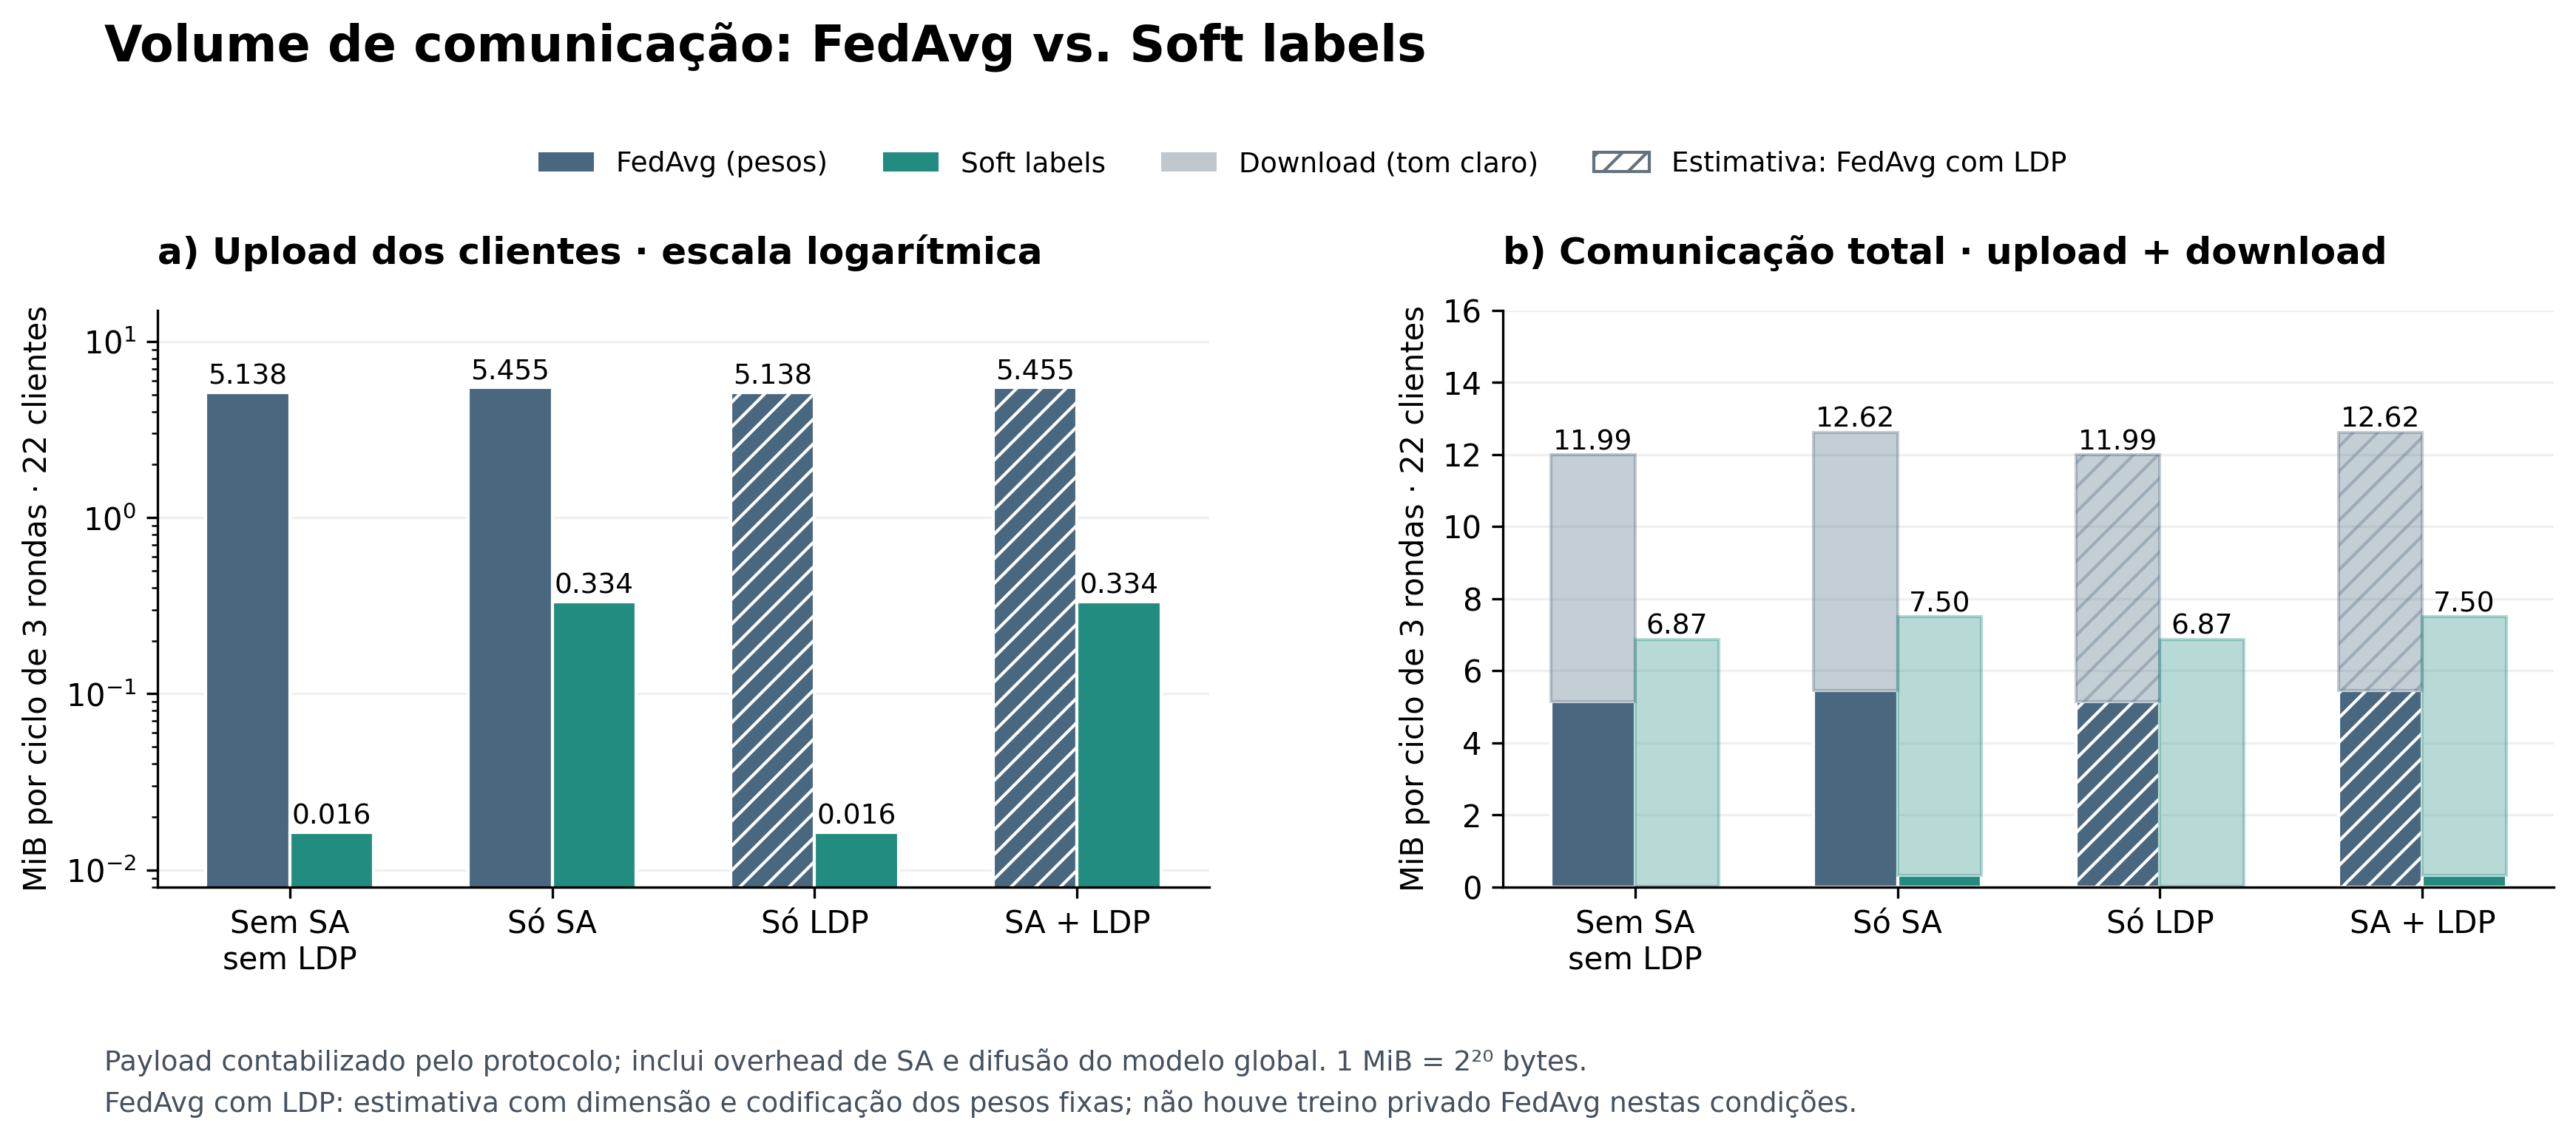

In [ ]:
from IPython.display import display, Image
from support.softlabels_privacy_comparison import OUT
display(Image(filename=str(OUT / "comunicacao_fedavg_softlabels.png")))

**Figura — Volume de comunicação de FedAvg e Soft labels nas quatro condições.** (a) Upload agregado dos 22 clientes, em escala logarítmica. (b) Upload e download, empilhados, incluindo a distribuição do modelo global e a comunicação de SA. Valores em MiB por ciclo de três rondas, média de cinco seeds; os volumes são constantes entre seeds nas condições registadas. Contabiliza-se a difusão inicial e as difusões após cada ronda, incluindo a final uma única vez. Os valores são bytes de payload contabilizados pelo protocolo, não tráfego medido na rede; não incluem cabeçalhos de transporte, retransmissões ou energia.

**Barras tracejadas:** não existem execuções FedAvg com LDP nestes resultados. As condições Só LDP e SA + LDP de FedAvg são estimativas que reutilizam, respetivamente, os volumes sem SA e com SA, sob a hipótese de que a perturbação local mantém o número de pesos e a sua codificação. Não se aplica o mecanismo P2 de logits aos pesos nem se afirma uma garantia DP para essas estimativas. Em Soft labels usam-se os registos efetivos de P2 e P2 + SA: a margem LDP é reconvertida em 64 probabilidades antes da transmissão, sem redução da dimensão do payload.

**Interpretação:** Soft labels reduz fortemente o upload face ao envio de pesos de FedAvg. A redução na comunicação total é menor, pois ambos distribuem a mesma CNN1D global. SA acrescenta overhead nos dois métodos. Quantidade de bytes não mede quantidade semântica de informação sensível nem constitui uma métrica de privacidade. As arquiteturas e objetivos locais diferem, pelo que o gráfico compara comunicação, não equivalência de utilidade ou de custo computacional.

## Síntese final — utilidade, proteção e volume enviado por ronda

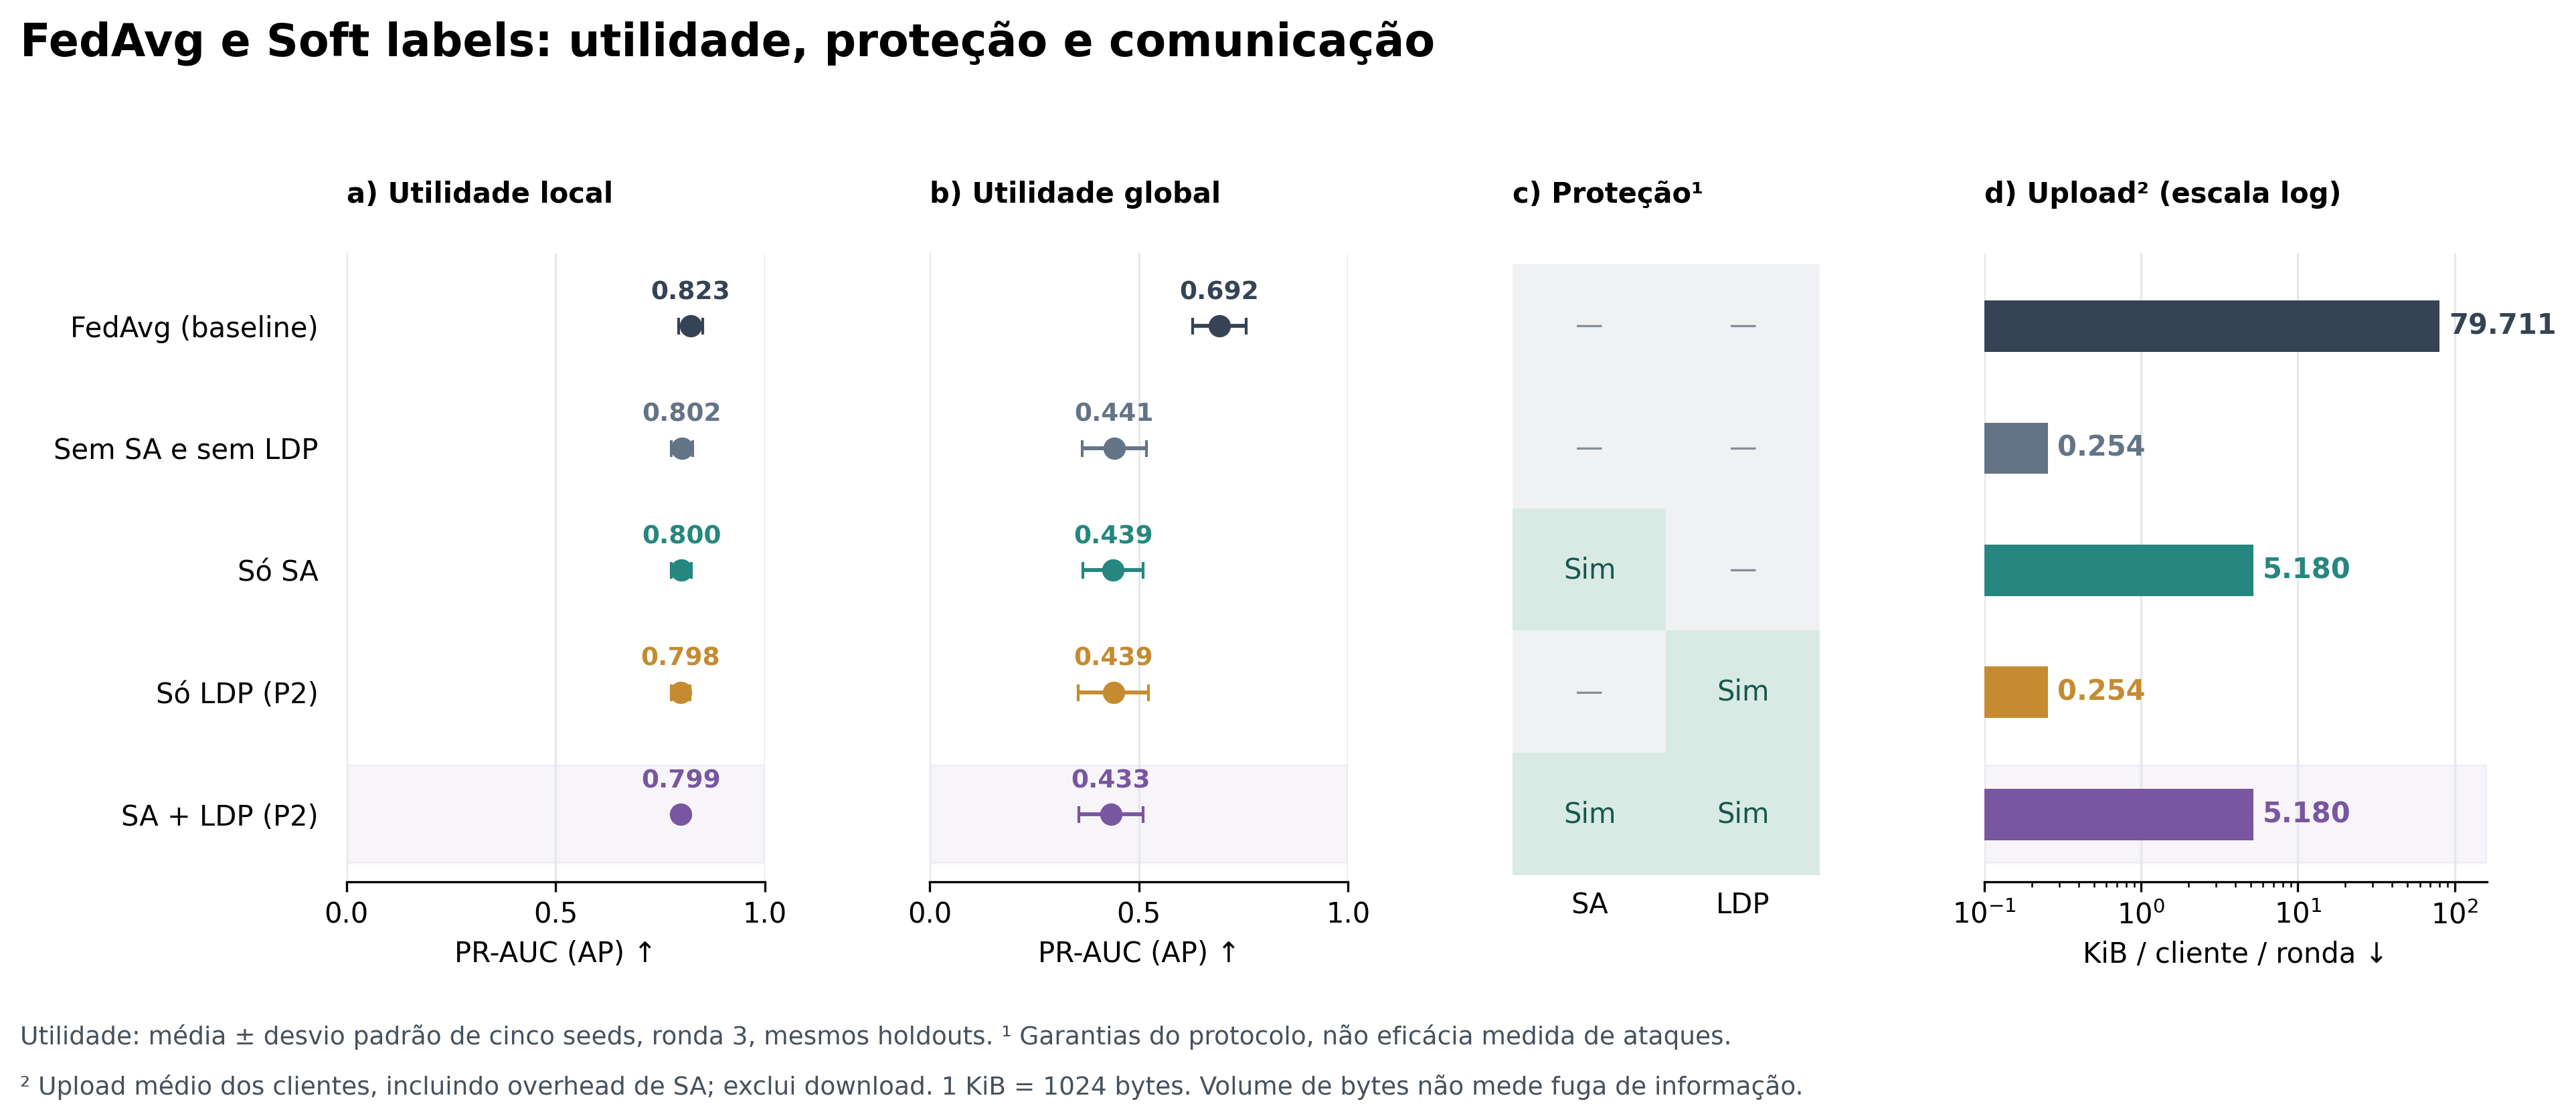

In [ ]:
from IPython.display import display, Image
from support.softlabels_privacy_comparison import OUT
display(Image(filename=str(OUT / "sintese_final_por_ronda.png")))

## Slide 2 — privacidade e utilidade da configuração final

A figura apresenta o ponto de operação escolhido, não uma curva de desempenho para vários valores de ε. A referência é Soft labels sem SA nem LDP. As barras representam o desvio padrão entre seeds, não intervalos de confiança. A comparação não isola causalmente o efeito de cada mecanismo.

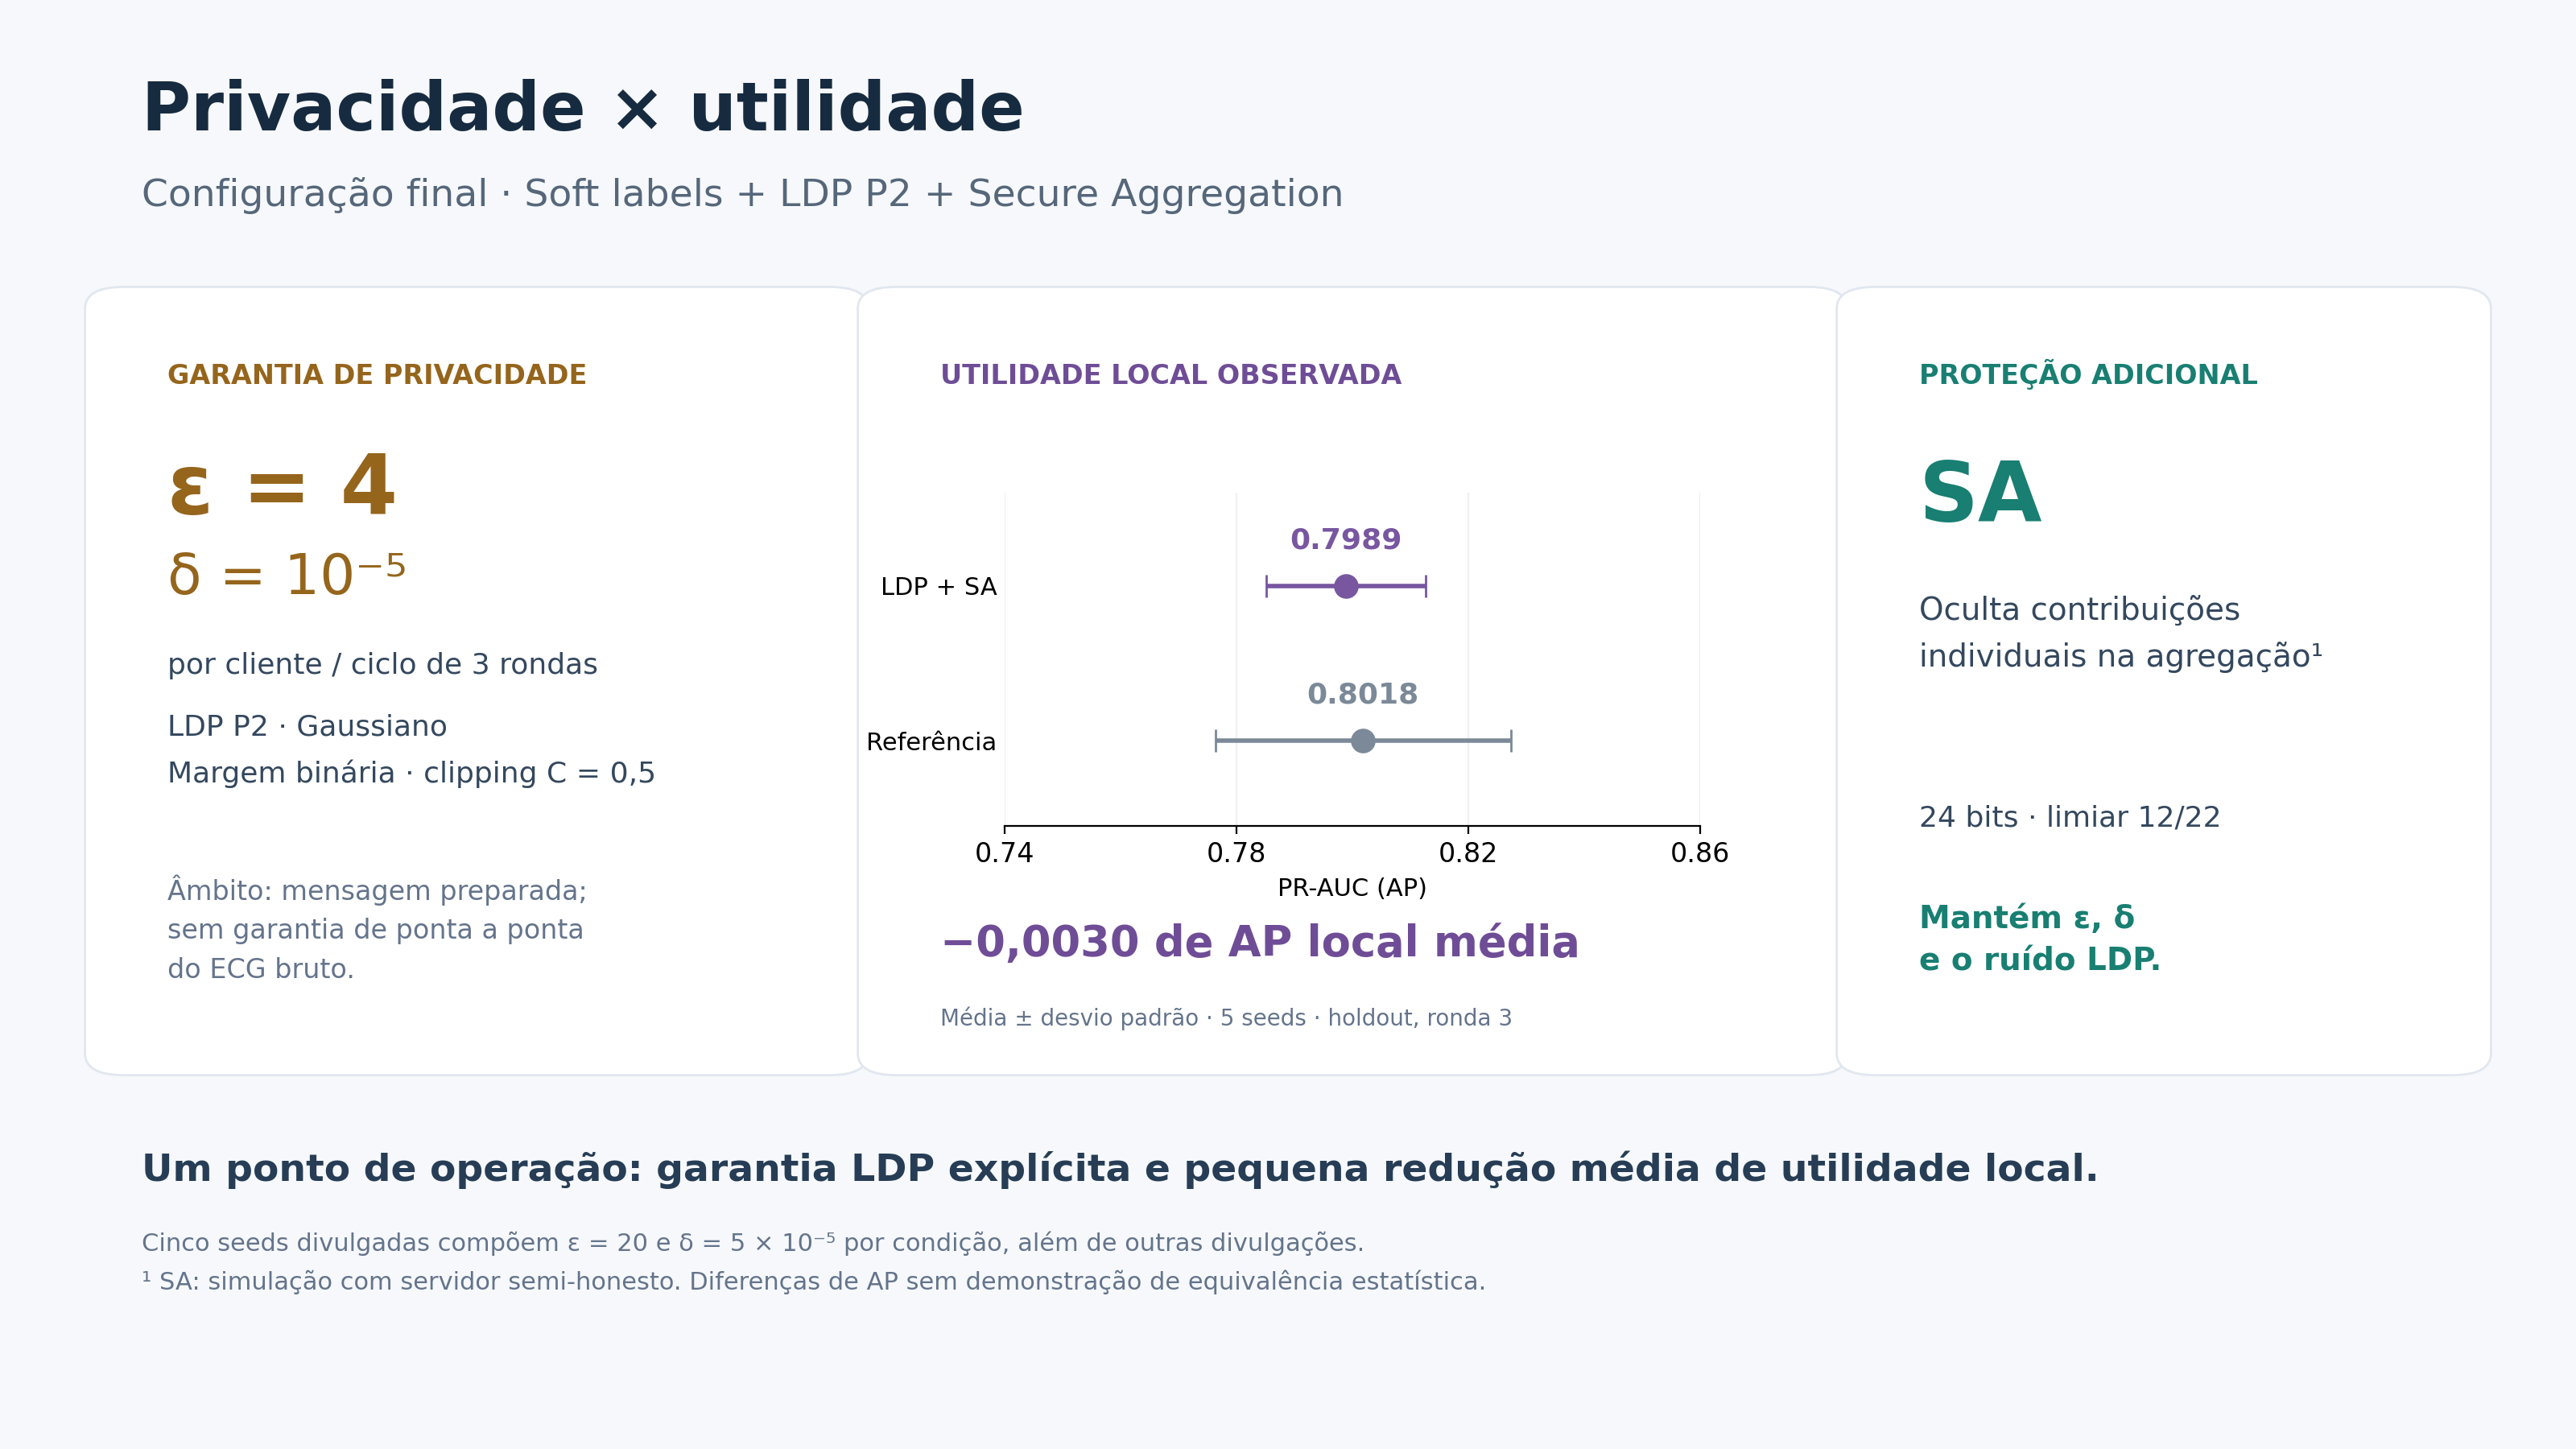

In [ ]:
from IPython.display import display, Image
from support.softlabels_privacy_comparison import OUT
display(Image(filename=str(OUT / "slide_privacidade_utilidade.png")))

**Baseline FedAvg:** a primeira linha usa os registos de FedAvg sem SA nem LDP, nos mesmos clientes, holdouts, seeds e ronda final. O upload envia pesos; as restantes linhas enviam soft labels. As arquiteturas e objetivos de treino locais diferem entre métodos. O painel de upload usa escala logarítmica para acomodar a diferença de volume.

**Figura — Síntese de utilidade, proteção e volume enviado por ronda nas quatro configurações de Soft labels.** (a–b) PR-AUC local e global: média ± desvio padrão amostral entre cinco seeds na ronda 3; métricas por cliente ponderadas pelos exemplos de fit, nos mesmos holdouts dos 22 clientes de treino. Não são métricas de test nem AP pooled. (c) Presença das proteções SA e LDP, sem pontuação artificial de privacidade. SA oculta contribuições durante a agregação nas hipóteses da simulação com servidor semi-honesto, com 24 bits e limiar 12/22. LDP P2 perturba a mensagem preparada, com mecanismo Gaussiano, margem, C=0,5, ε=4 e δ=10⁻⁵ por cliente/ciclo; o orçamento é igual com ou sem SA e a composição das cinco seeds é ε=20, δ=5×10⁻⁵ por condição privada, além das restantes divulgações. Não se demonstra privacidade de ponta a ponta do ECG bruto nem resistência a envenenamento.

(d) Upload médio por cliente e por ronda, calculado a partir dos registos das três rondas e cinco seeds. Os volumes são constantes entre rondas nas condições registadas. Inclui a contribuição e as mensagens de SA contabilizadas no upload; exclui download, cabeçalhos de rede e retransmissões. Sem SA: **0,254 KiB/cliente/ronda** (**5,586 KiB/ronda** no conjunto dos 22 clientes). Com SA: **5,180 KiB/cliente/ronda** (**113,953 KiB/ronda** no conjunto). LDP mantém o volume transmitido neste protocolo, que envia 64 probabilidades após reconversão das margens. Os bytes medem volume de comunicação, não informação sensível revelada.

**Leitura do compromisso:** SA + LDP combina as duas proteções com AP local média de 0,7989, próxima de 0,8018 na referência, mas aumenta o upload devido ao overhead de SA. A utilidade global é inferior à local e variável entre seeds. Os resultados não demonstram equivalência estatística; o ruído independente entre condições privadas impede isolar o efeito de SA. A adequação a wearables exige ainda medir energia, latência e desempenho em utilização real.